C:\Users\htom8


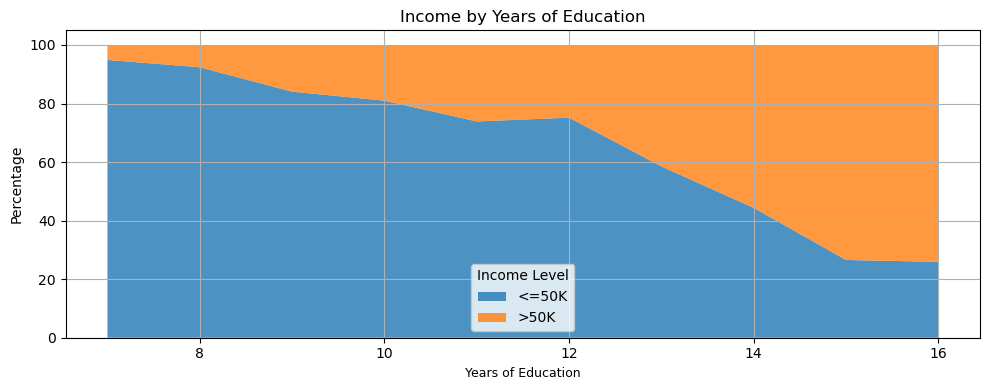

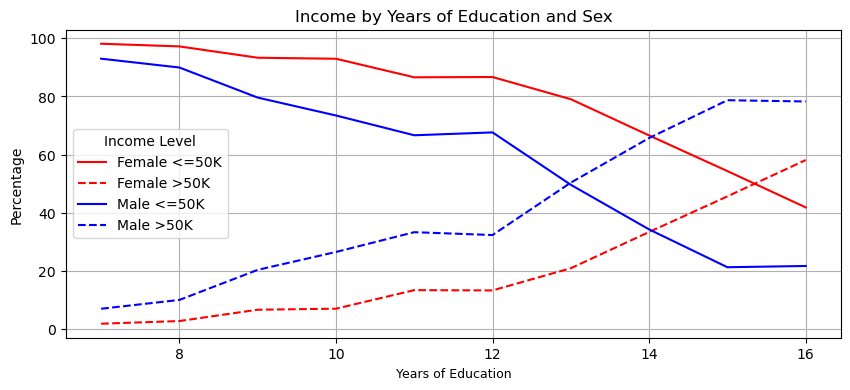

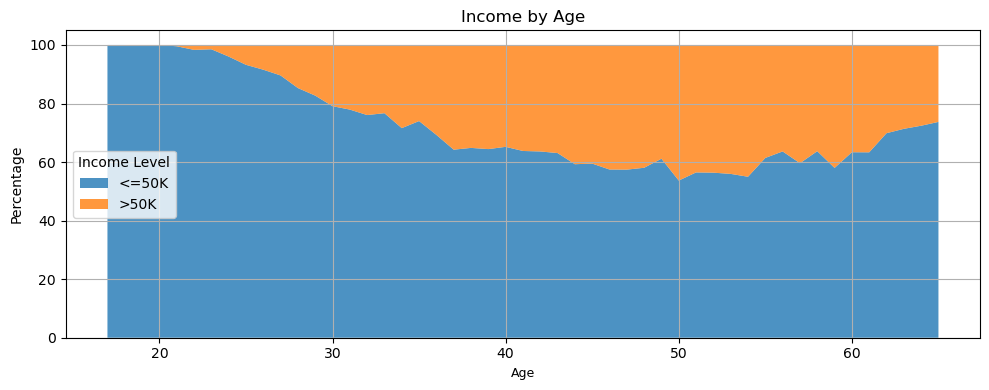

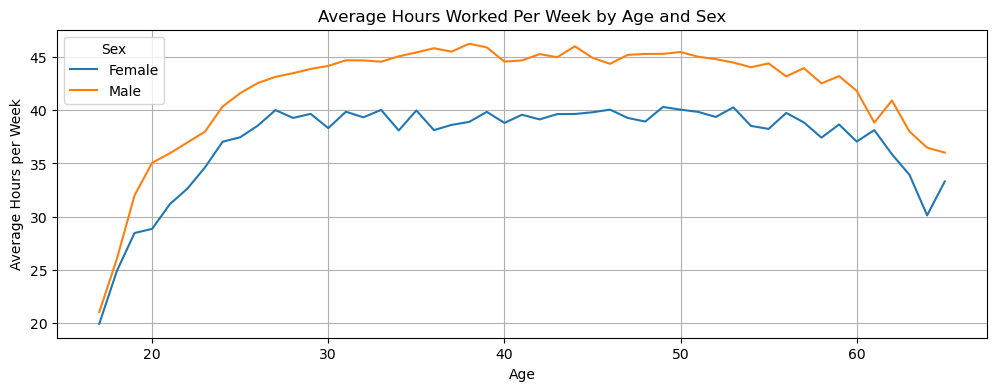

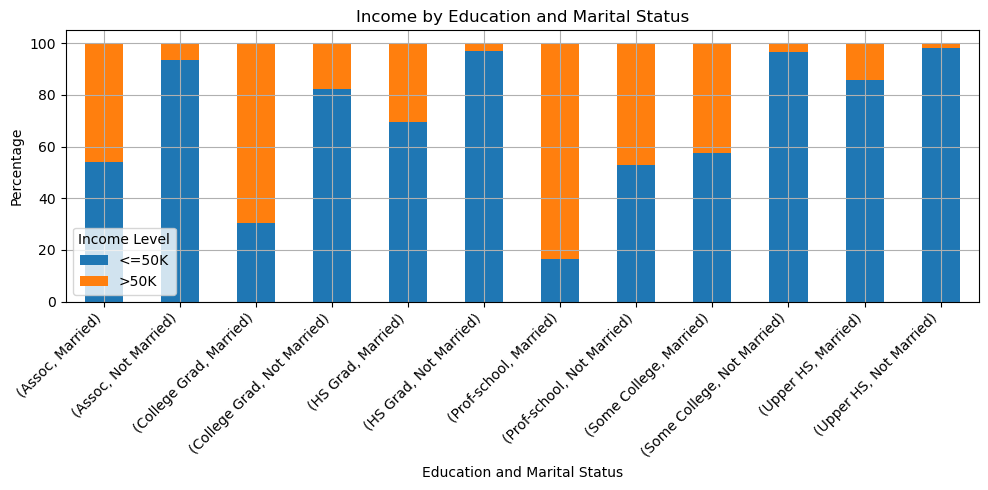

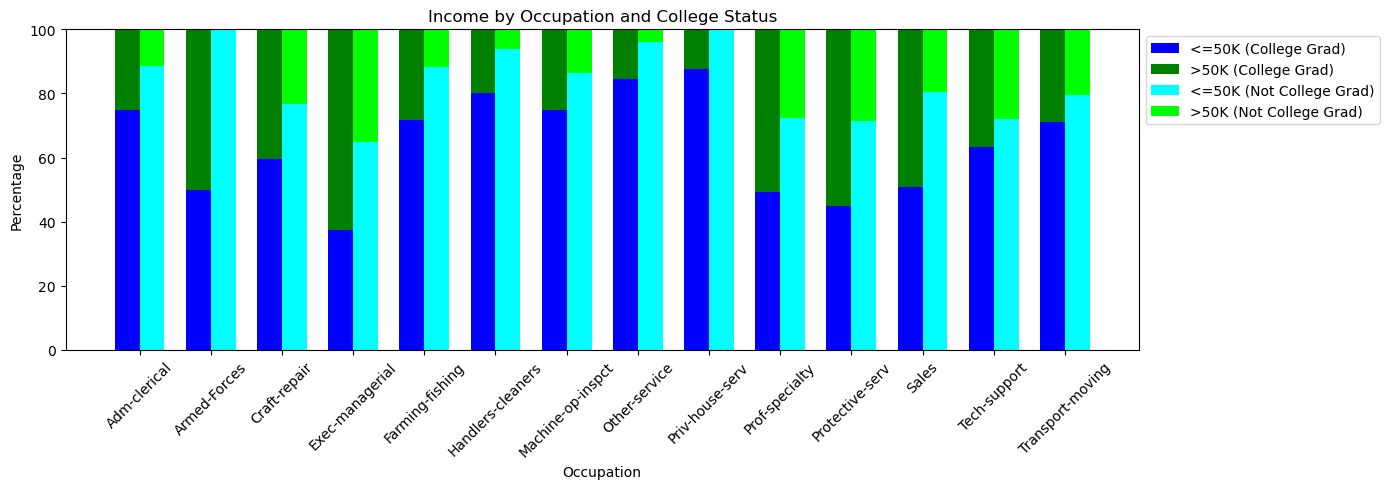

In [ ]:
#!/usr/bin/env python
# coding: utf-8

# Import necessary libraries for data manipulation and visualization
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

# Print the current working directory (useful for debugging)
print(os.getcwd())

# Define column names for the dataset
column_names = [
    'age', 'workclass', 'fnlwgt', 'education', 'ed_years',
    'marital_status', 'occupation', 'relationship', 'race', 'sex',
    'cap_gain', 'cap_loss', 'hrs_per_week', 'native_country', 'income'
]

# Load the dataset and assign column names
ad = pd.read_csv('adult.data', header=None, names=column_names, skipinitialspace=True)

# Drop unnecessary columns that will not be used in the analysis
ad.drop(columns=['fnlwgt', 'cap_gain', 'cap_loss'], inplace=True)

# -------------------------
# Categorizing Age Groups
# -------------------------
def categorize_age(age):
    """
    Categorize age into predefined age groups.
    Returns: '<25', '25 to 30', '31 to 35', '>35'
    """
    if age < 25:
        return '<25'
    elif 25 <= age <= 30:
        return '25 to 30'
    elif 31 <= age <= 35:
        return '31 to 35'
    else:
        return '>35'

# Apply age categorization
ad['age_cat'] = ad['age'].apply(categorize_age)

# -------------------------
# Mapping Education Levels
# -------------------------
# This mapping groups various education levels into broader categories for better visualization.
education_map = {
    'Bachelors': 'College Grad', 'Masters': 'College Grad', 'Doctorate': 'College Grad', 
    'Prof-school': 'Prof-school', 'Some-college': 'Some College', 'HS-grad': 'HS Grad',
    '11th': 'Upper HS', '12th': 'Upper HS', 'Assoc-acdm': 'Assoc', 'Assoc-voc': 'Assoc',
    '7th-8th': 'Lower Grade', '9th': 'Lower Grade', '10th': 'Lower Grade',
    '5th-6th': 'Lower Grade', '1st-4th': 'Lower Grade', 'Preschool': 'Lower Grade'
}

# Apply education mapping
ad['ed_category'] = ad['education'].map(education_map)

# Remove 'Lower Grade' category to focus on relevant education levels
ad = ad[ad['ed_category'] != 'Lower Grade']

# -------------------------
# Mapping Marital Status
# -------------------------
# This mapping consolidates marital status into 'Married' and 'Not Married' categories.
marital_map = {
    'Never-married': 'Not Married', 'Married-civ-spouse': 'Married',
    'Married-AF-spouse': 'Married', 'Married-spouse-absent': 'Married',
    'Divorced': 'Not Married', 'Separated': 'Not Married', 'Widowed': 'Not Married'
}

# Apply marital status mapping
ad['marital_category'] = ad['marital_status'].map(marital_map)


# -------------------------
# Mapping College_Status
# -------------------------
# Dictionary to map education data to a more generalize education level
# This will help to better visulazaion less clutter and without lossing informaiton.
college_stat_map = { 'Bachelors' : 'College Grad',
                  'HS-grad' : 'Not College Grad', 
                  '11th': 'Not College Grad',
                  '12th': 'Not College Grad',
                  'Masters' : 'College Grad', 
                  'Some-college' : 'Not College Grad',
                   'Assoc-acdm' : 'Not College Grad',
                   'Assoc-voc' : 'Not College Grad',
                   'Doctorate': 'College Grad',
                   'Prof-school' : 'College Grad',
                   '7th-8th' :  'Lower Grade',
                   '9th' : 'Lower Grade',
                   '5th-6th' : 'Lower Grade',
                   '10th' : 'Lower Grade', 
                   '1st-4th' : 'Lower Grade',
                   'Preschool' : 'Lower Grade'
                }

ad2 = ad.copy()
ad2['College_Status'] = ad2['education'].map(college_stat_map)
ad2 = ad2[ ad2['College_Status'] != 'Lower Grade' ]
ad = ad2.copy()


# -------------------------
# FIGURE 1: Stacked Area Chart - Income by Years of Education
# -------------------------
# Pivot table to compute income distribution by years of education
pivot = ad.pivot_table(index=['ed_years'], columns='income', aggfunc='size', fill_value=0).reset_index()

# Convert counts to percentages for better comparison
pivot_percent = pivot.set_index('ed_years').div(pivot.set_index('ed_years').sum(axis=1), axis=0) * 100

# Plot stacked area chart
fig, ax = plt.subplots(figsize=(10, 4))
ax.stackplot(pivot_percent.index, pivot_percent.T, labels=pivot_percent.columns, alpha=0.8)

# Labels and title
plt.xlabel('Years of Education', fontsize=9)
plt.ylabel('Percentage')
plt.title('Income by Years of Education')
plt.legend(title='Income Level', loc='lower center')
plt.grid(True)
plt.tight_layout()
plt.show()

# -------------------------
# FIGURE 2: Line Chart - Income by Education and Gender
# -------------------------
# Create a new column combining sex and income status
ad['sex_income'] = ad['sex'] + ' ' + ad['income']

# Pivot table to compute percentage income distribution by education and gender
pivot = ad.pivot_table(index=['ed_years'], columns='sex_income', aggfunc='size', fill_value=0).reset_index()

# Compute percentage values
for gender in ['Male', 'Female']:
    pivot[f'{gender} Count'] = pivot[f'{gender} <=50K'] + pivot[f'{gender} >50K']
    pivot[f'{gender} <=50K'] = pivot[f'{gender} <=50K'] / pivot[f'{gender} Count'] * 100
    pivot[f'{gender} >50K'] = pivot[f'{gender} >50K'] / pivot[f'{gender} Count'] * 100
    pivot.drop(columns=[f'{gender} Count'], inplace=True)

# Define custom styles
styles = {
    'Male <=50K': {'color': 'blue', 'linestyle': '-'},
    'Male >50K': {'color': 'blue', 'linestyle': '--'},
    'Female <=50K': {'color': 'red', 'linestyle': '-'},
    'Female >50K': {'color': 'red', 'linestyle': '--'}
}

# Plot line graph
fig, ax = plt.subplots(figsize=(10, 4))
for column in pivot.columns[1:]:
    plt.plot(pivot['ed_years'], pivot[column], label=column, color=styles[column]['color'], linestyle=styles[column]['linestyle'])

plt.xlabel('Years of Education', fontsize=9)
plt.ylabel('Percentage')
plt.title('Income by Years of Education and Sex')
plt.legend(title='Income Level', loc='center left', bbox_to_anchor=(0, 0.5))
plt.grid(True)
plt.show()

# -------------------------
# FIGURE 3: Area Graph - Income by Age
# -------------------------
# Pivot table to compute income distribution by age
pivot = ad.loc[ad['age'] <= 65].pivot_table(index=['age'], columns='income', aggfunc='size', fill_value=0).reset_index()

# Convert counts to percentages
pivot_percent = pivot.set_index('age').div(pivot.set_index('age').sum(axis=1), axis=0) * 100

# Plot stacked area graph
fig, ax = plt.subplots(figsize=(10, 4))
ax.stackplot(pivot_percent.index, pivot_percent.T, labels=pivot_percent.columns, alpha=0.8)

plt.xlabel('Age', fontsize=9)
plt.ylabel('Percentage')
plt.title('Income by Age')
plt.legend(title='Income Level', loc='center left', bbox_to_anchor=(0, 0.5))
plt.grid(True)
plt.tight_layout()
plt.show()

# -------------------------
# FIGURE 4: Line Graph - Average Hours Worked by Age and Gender
# -------------------------
# Compute average hours worked per week by age and gender
avg_hours_by_age_sex = ad[ad['age'] <= 65].groupby(['age', 'sex'])['hrs_per_week'].mean().unstack()

# Plot line graph
avg_hours_by_age_sex.plot(kind='line', figsize=(12, 4))

plt.title('Average Hours Worked Per Week by Age and Sex')
plt.xlabel('Age')
plt.ylabel('Average Hours per Week')
plt.legend(title='Sex')
plt.grid(True)
plt.show()

# -------------------------
# FIGURE 5: Stacked Bar Chart - Income by Education and Marital Status
# -------------------------
# Pivot table for income distribution by education and marital status
ad2 = ad.pivot_table(index=['ed_category', 'marital_category'], columns='income', aggfunc='size', fill_value=0).reset_index()

# Convert counts to percentages
ad2['Total'] = ad2['<=50K'] + ad2['>50K']
ad2['<=50K'] = ad2['<=50K'] / ad2['Total'] * 100
ad2['>50K'] = ad2['>50K'] / ad2['Total'] * 100
ad2.drop(columns=['Total'], inplace=True)

# Plot stacked bar chart
fig, ax = plt.subplots(figsize=(10, 5))
ad2.set_index(['ed_category', 'marital_category']).plot(kind="bar", stacked=True, ax=ax)
plt.title("Income by Education and Marital Status")
plt.ylabel("Percentage")
plt.xlabel("Education and Marital Status")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Income Level")
plt.grid(True)
plt.tight_layout()
plt.show()


# -------------------------
# FIGURE 6: Stacked Bar Chart - Income by Occupation and College Status
# -------------------------

# Create Stack grpahs for Income by Occupation and College Status
# Filter out occuption that are not define
ad2 = ad[ ad['occupation'] != '?' ].pivot_table(
    index=['occupation', 'College_Status'],
    columns='income', aggfunc='size', fill_value=0
).reset_index()

# Calculate percentage
ad2['count'] = ad2['<=50K'] + ad2['>50K']
ad2["<=50K"] = ad2['<=50K'] / ad2['count'] * 100
ad2[">50K"] = ad2['>50K'] / ad2['count'] * 100
ad2.drop(columns=['count'], inplace=True)

occupations = ad2['occupation'].unique()
college_grad = ad2[ad2['College_Status'] == 'College Grad']
non_college_grad = ad2[ad2['College_Status'] == 'Not College Grad']

x = np.arange(len(occupations))  # the label locations
width = 0.35  # the width of the bars

fig, ax = plt.subplots(figsize=(14, 5))

# Plot bars for college graduates
rects1 = ax.bar(x - width/2, college_grad['<=50K'], width, label='<=50K (College Grad)', color='b')
rects2 = ax.bar(x - width/2, college_grad['>50K'], width, bottom=college_grad['<=50K'], label='>50K (College Grad)', color='g')

# Plot bars for non-college graduates on the same bars
rects3 = ax.bar(x + width/2, non_college_grad['<=50K'], width, label='<=50K (Not College Grad)', color='cyan')
rects4 = ax.bar(x + width/2, non_college_grad['>50K'], width, bottom=non_college_grad['<=50K'], label='>50K (Not College Grad)', color='lime')

ax.set_xlabel('Occupation')
ax.set_ylabel('Percentage')
ax.set_title('Income by Occupation and College Status')
ax.set_xticks(x)
ax.set_xticklabels(occupations, rotation=45)
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))

fig.tight_layout()

plt.show()
